In [78]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
    roc_auc_score
)
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import ElasticNetCV

In [79]:
Prestamos = pd.read_excel("Prestamos_Data_Alumnos_v5.xlsx")   
Diccionario_variables_alumnos = pd.read_excel("Diccionario_Variables_Alumnos.xlsx")

In [80]:
#filtrar el proposito por educacion
Prestamos_educacion = Prestamos[Prestamos["Proposito"] == "Educación"]

In [81]:
# pasamos las comumnas a tipo int porque son categoricas y no tienen decimales, por lo que no tiene sentido que sean float.
Prestamos_educacion['Posesion_Hipoteca'] = Prestamos_educacion['Posesion_Hipoteca'].astype(int)
Prestamos_educacion['Personas_Cargo'] = Prestamos_educacion['Personas_Cargo'].astype(int)
Prestamos_educacion['Fiador'] = Prestamos_educacion['Fiador'].astype(int)
Prestamos_educacion['Duracion'] = Prestamos_educacion['Duracion'].astype(int)
Prestamos_educacion['Meses_Empleo'] = Prestamos_educacion['Meses_Empleo'].astype(int)
Prestamos_educacion['Ingresos'] = Prestamos_educacion['Ingresos'].astype(int)

C:\Users\Oier\AppData\Local\Temp\ipykernel_16344\1568429427.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Prestamos_educacion['Posesion_Hipoteca'] = Prestamos_educacion['Posesion_Hipoteca'].astype(int)
C:\Users\Oier\AppData\Local\Temp\ipykernel_16344\1568429427.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Prestamos_educacion['Personas_Cargo'] = Prestamos_educacion['Personas_Cargo'].astype(int)
C:\Users\Oier\AppData\Local\Temp\ipykernel_16344\1568429427.py:4: SettingWithCopyWarning: 
A value is 

In [82]:
#esta columna es ruido no aporta nada al modelo, por lo que la eliminamos
Prestamos_educacion = Prestamos_educacion.drop(columns=["Proposito"])

In [83]:
Prestamos_educacion.duplicated().sum()

np.int64(1)

In [84]:
#eliminar los duplicados de la base de datos Prestamos_educacion por lo que no aporta nada al modelo, por lo que la eliminamos 
Prestamos_educacion.drop_duplicates(inplace=True)

In [85]:
#aunque haya pocos valores nulos,vamos a tratarlos en vez de eliminarlos, ya que no queremos perder datos, por lo que vamos a rellenarlos con la mediana de la columna.
Prestamos_educacion["Ratio_Interes"] = Prestamos_educacion["Ratio_Interes"].fillna(
    Prestamos_educacion["Ratio_Interes"].median())

In [86]:
Prestamos_educacion["Estudios"] = Prestamos_educacion["Estudios"].fillna(
    Prestamos_educacion["Estudios"].mode()[0])

In [87]:
orden_estudios = {
    "Escolar": 0,
    "Grado Universitario": 1,
    "Máster": 2,
    "Doctorado": 3
}

Prestamos_educacion["Estudios"] = Prestamos_educacion["Estudios"].str.strip()
Prestamos_educacion["Estudios_encoded"] = Prestamos_educacion["Estudios"].map(orden_estudios)

print(Prestamos_educacion[["Estudios", "Estudios_encoded"]].value_counts())

Estudios             Estudios_encoded
Escolar              0                   69818
Grado Universitario  1                   66497
Máster               2                   28091
Doctorado            3                   14202
Name: count, dtype: int64


In [88]:
Prestamos_educacion = Prestamos_educacion.drop(columns=["Estudios"])

In [89]:
Prestamos_educacion["Estado_Civil"] = Prestamos_educacion["Estado_Civil"].str.strip().str.capitalize()
Prestamos_educacion = pd.get_dummies(
    Prestamos_educacion,
    columns=["Estado_Civil"],
    dtype=int,
    drop_first=True
)

In [90]:
Prestamos_educacion["Tipo_Jornada_Laboral"] = Prestamos_educacion["Tipo_Jornada_Laboral"].str.strip().str.capitalize()
Prestamos_educacion = pd.get_dummies(
    Prestamos_educacion,
    columns=["Tipo_Jornada_Laboral"],
    dtype=int,
    drop_first=True
)

In [91]:
porcentaje = pd.DataFrame({
        "Frecuencia": Prestamos_educacion['Impago'].value_counts(),
        "Porcentaje": (
            Prestamos_educacion['Impago']
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
        )
    })
porcentaje

,Frecuencia,Porcentaje
Impago,,
0,157833,88.37
1,20775,11.63


La variable impago detecta que el 88,37% no son impagos y que el 11,63% son impagos

## Modelo

el modelo usado es una regresion logistica ya que la variable a predecir es impago ,la cual es binaria (1 o 0).

In [92]:
copia= Prestamos_educacion.copy()
#hacemos una copia de los datos para poder probar diferentes modelos y no perder los datos originales.

In [93]:
X= copia.drop(columns=["Impago","ID","Prima"])
y= copia["Impago"]

eliminamos de la variable x las columnas id ya que no aporta ninguna información util al modelo , la columna Imapago ya que es la variable dependiente y la columna prima porque cuando viene un nuevo cliente no conoces su prima por lo que esa información no interesa al momento de calcular el riesgo de impago de un cliente

Text(0.5, 1.0, 'Correlación')

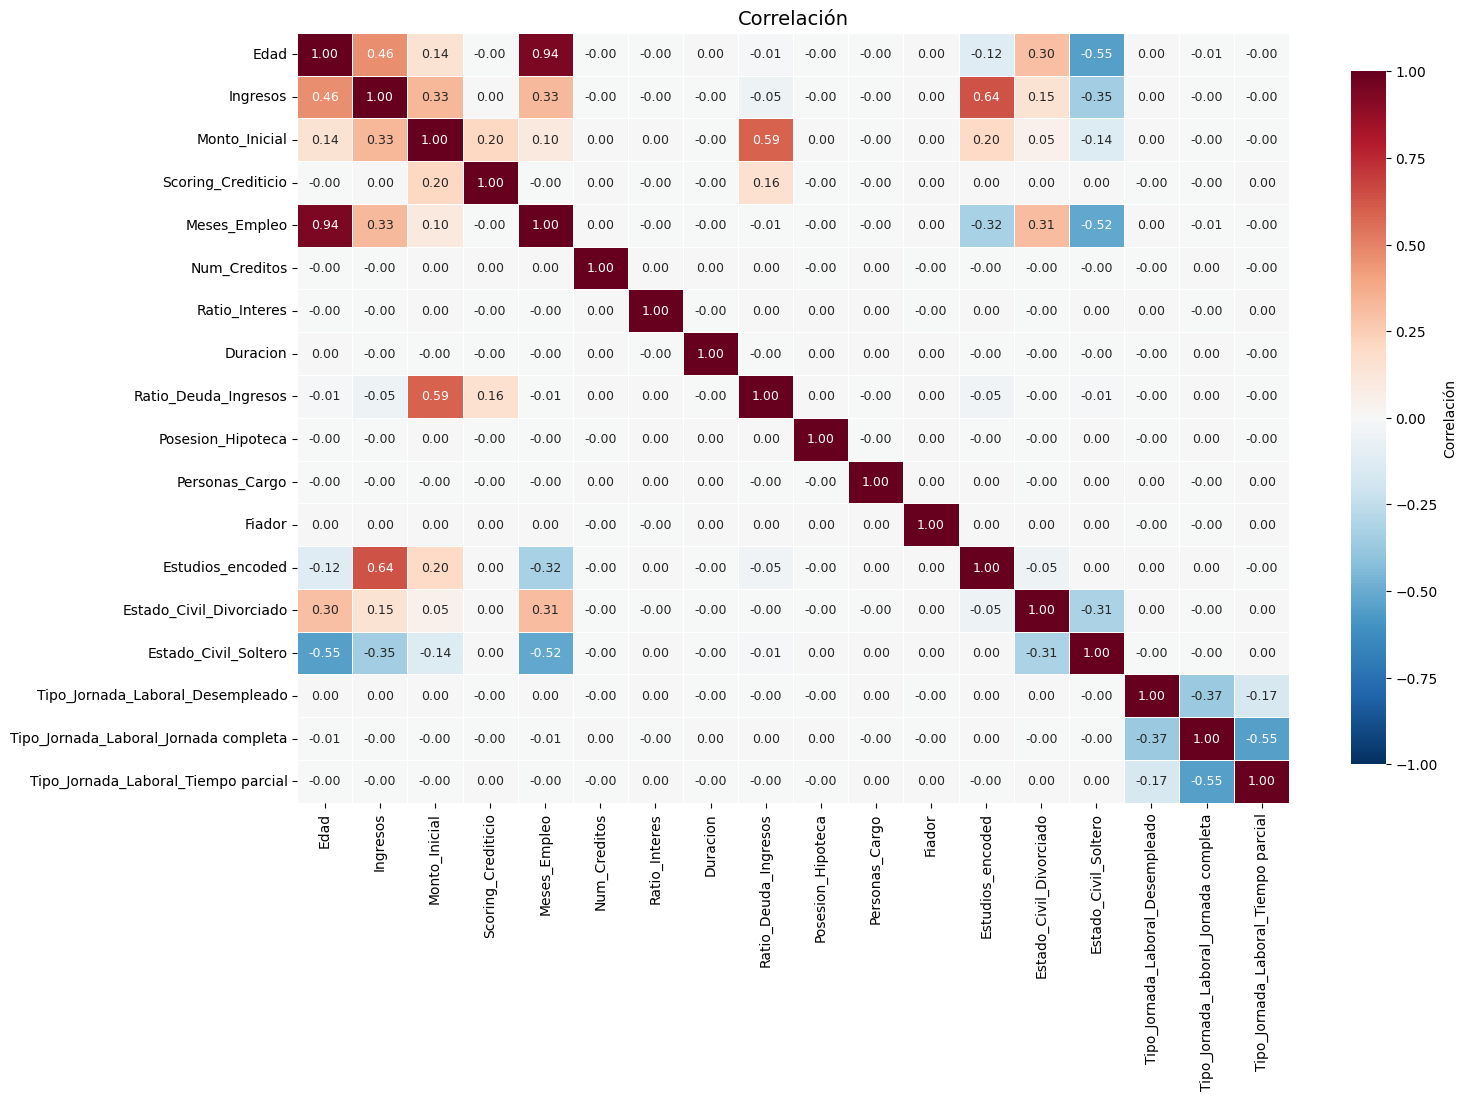

In [94]:
corr = X.corr()

plt.figure(figsize=(16, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.7,
    linecolor="white",
    annot_kws={"size": 9},
    cbar_kws={"label": "Correlación", "shrink": 0.9}
)

plt.title(
    "Correlación",
    fontsize=14)

In [95]:
X_train, X_test, y_train, y_test= train_test_split(X,y,train_size=0.8,random_state=42,shuffle=True,stratify=y)

In [96]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)

In [97]:
X_test_scaled = scaler.transform(X_test)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

In [98]:
X_train_scaled = sm.add_constant(X_train_scaled, prepend=True, has_constant='add')

modelo_log_statsm = sm.Logit(endog=y_train, exog=X_train_scaled)
modelo_log_statsm = modelo_log_statsm.fit(disp=False, maxiter=100)

print(modelo_log_statsm.summary())

                           Logit Regression Results                           
Dep. Variable:                 Impago   No. Observations:               142886
Model:                          Logit   Df Residuals:                   142867
Method:                           MLE   Df Model:                           18
Date:                Wed, 28 Oct 2026   Pseudo R-squ.:                 0.06597
Time:                        14:22:47   Log-Likelihood:                -47982.
converged:                       True   LL-Null:                       -51371.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                    -2.2150      0.010   -229.843      0.000      -2.234      -2.196
Edad                                     -0.3106  

In [99]:
tabla_coeficientes = pd.DataFrame({
    'Coeficiente': modelo_log_statsm.params,
    'p_valor': modelo_log_statsm.pvalues
})

tabla_coeficientes.sort_values('p_valor')

,Coeficiente,p_valor
const,-2.214951,0.000000e+00
Ratio_Interes,0.408161,0.000000e+00
Scoring_Crediticio,-0.102861,6.009891e-34
Edad,-0.310599,8.288603e-18
Meses_Empleo,-0.268752,5.075602e-12
Monto_Inicial,-0.064579,1.272546e-06
Posesion_Hipoteca,-0.009383,2.687899e-01
Estudios_encoded,-0.016107,3.625454e-01
Tipo_Jornada_Laboral_Jornada completa,0.010515,3.962261e-01
Tipo_Jornada_Laboral_Tiempo parcial,0.008934,4.429805e-01


In [100]:
X_test_scaled = sm.add_constant(X_test_scaled, has_constant='add')

predicciones = modelo_log_statsm.predict(exog=X_test_scaled)
clasificacion = np.where(predicciones < 0.5, 0, 1)

predicciones.head()

306148    0.119160
157121    0.035214
74572     0.144884
354050    0.084658
337716    0.109042
dtype: float64

In [101]:
acierto = accuracy_score(y_test, clasificacion)
print('Acierto:', round(acierto * 100, 2), '%')
print('Error:', round((1 - acierto) * 100, 2), '%')

print(classification_report(y_test, clasificacion, zero_division=0))

Acierto:

 88.37 %
Error: 11.63 %
              precision    recall  f1-score   support

           0       0.88      1.00      0.94     31567
           1       0.50      0.00      0.00      4155

    accuracy                           0.88     35722
   macro avg       0.69      0.50      0.47     35722
weighted avg       0.84      0.88      0.83     35722



In [102]:
resultados = pd.DataFrame({
    'Impago_real': y_test,
    'Probabilidad_impago': predicciones,
    'Prediccion_impago': clasificacion
})

if 'ID' in copia.columns:
    resultados.insert(0, 'ID', copia.loc[resultados.index, 'ID'])

resultados.head(10)

,ID,Impago_real,Probabilidad_impago,Prediccion_impago
306148,7DP3TA,0,0.119160,0
157121,1W81WI,0,0.035214,0
74572,O4B9SC,0,0.144884,0
354050,Y2KDXV,1,0.084658,0
337716,JKMM5V,0,0.109042,0
312365,5L4RMV,0,0.118772,0
480420,CE65SQ,0,0.154594,0
441053,79IMHD,0,0.032635,0
67638,NKEV1T,0,0.146740,0
293646,1QHCLN,0,0.213790,0


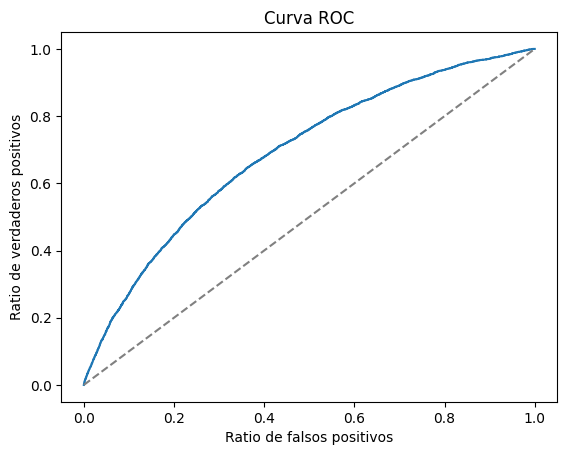

ROC-AUC: 0.691


In [103]:
fpr, tpr, threshold = roc_curve(y_test, predicciones)

plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('Ratio de falsos positivos')
plt.ylabel('Ratio de verdaderos positivos')
plt.title('Curva ROC')
plt.show()

print('ROC-AUC:', round(roc_auc_score(y_test, predicciones), 3))

## REGULARIZACION

In [104]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Quitamos la constante que habíamos añadido para statsmodels
X_train_reg = X_train_scaled.drop(columns=["const"], errors="ignore")
X_test_reg = X_test_scaled.drop(columns=["const"], errors="ignore")

# Comprobamos las dimensiones
print("Entrenamiento:", X_train_reg.shape)
print("Test:", X_test_reg.shape)

Entrenamiento: (142886, 18)
Test: (35722, 18)


In [105]:
# Definimos el modelo de regresión logística regularizada
modelo_regularizado = LogisticRegression(
    penalty="elasticnet",
    solver="saga",
    max_iter=10000,
    random_state=42
)

# Valores que vamos a probar
parametros = {
    "C": [0.01, 0.1, 1, 10],
    "l1_ratio": [0.1, 0.5, 0.9]
}

# Validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Buscamos la mejor combinación
busqueda = GridSearchCV(
    estimator=modelo_regularizado,
    param_grid=parametros,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1
)

busqueda.fit(X_train_reg, y_train)

# Modelo con los mejores parámetros
modelo_regularizado = busqueda.best_estimator_

print("Mejores parámetros:", busqueda.best_params_)
print("Mejor Average Precision en validación:", round(busqueda.best_score_, 4))

Mejores parámetros: {'C': 0.01, 'l1_ratio': 0.9}
Mejor Average Precision en validación: 0.2221


In [106]:
# Probabilidad de impago (clase 1)
probabilidades_impago = modelo_regularizado.predict_proba(
    X_test_reg
)[:, 1]

# Clasificación utilizando el umbral 0.5
clasificacion_regularizada = np.where(
    probabilidades_impago >= 0.5, 1, 0
)

print("Primeras probabilidades:", probabilidades_impago[:15])
print("Primeras clasificaciones:", clasificacion_regularizada[:15])

Primeras probabilidades: [0.11778989 0.03458167 0.14293306 0.08333402 0.11095384 0.12288279
 0.15611858 0.03295669 0.14744487 0.21260579 0.04891982 0.02401386
 0.1711729  0.07892852 0.11251398]
Primeras clasificaciones: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [107]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

metricas = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Average Precision"
    ],
    "Valor": [
        accuracy_score(y_test, clasificacion_regularizada),
        precision_score(y_test, clasificacion_regularizada, zero_division=0),
        recall_score(y_test, clasificacion_regularizada, zero_division=0),
        f1_score(y_test, clasificacion_regularizada, zero_division=0),
        roc_auc_score(y_test, probabilidades_impago),
        average_precision_score(y_test, probabilidades_impago)
    ]
})

metricas["Valor"] = metricas["Valor"].round(4)

metricas

,Métrica,Valor
0,Accuracy,0.8837
1,Precision,0.5714
2,Recall,0.0010
3,F1-score,0.0019
4,ROC-AUC,0.6905
5,Average Precision,0.2247


In [118]:
from sklearn.model_selection import cross_val_predict

probabilidades_cv = cross_val_predict(
    modelo_regularizado,
    X_train_reg,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [108]:
resultados_regularizados = pd.DataFrame({
    "Impago_real": y_test,
    "Probabilidad_impago": probabilidades_impago,
    "Prediccion_impago": clasificacion_regularizada
})

resultados_regularizados["Probabilidad_impago"] = (
    resultados_regularizados["Probabilidad_impago"].round(4)
)

resultados_regularizados.head(10)

,Impago_real,Probabilidad_impago,Prediccion_impago
306148,0,0.1178,0
157121,0,0.0346,0
74572,0,0.1429,0
354050,1,0.0833,0
337716,0,0.1110,0
312365,0,0.1229,0
480420,0,0.1561,0
441053,0,0.0330,0
67638,0,0.1474,0
293646,0,0.2126,0


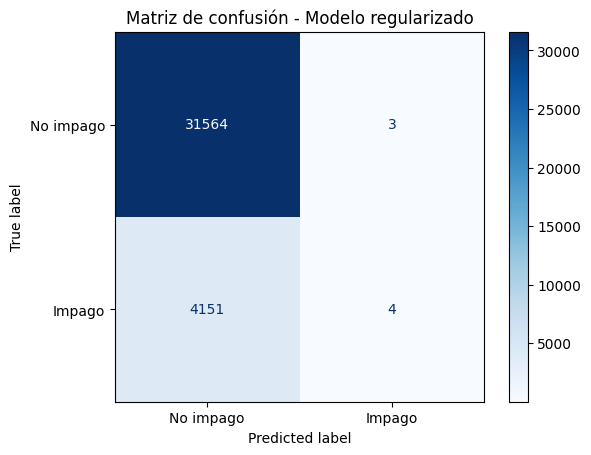

In [109]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz = confusion_matrix(
    y_test,
    clasificacion_regularizada,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["No impago", "Impago"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Modelo regularizado")
plt.show()

In [115]:
# Probabilidad de impago (clase 1)
probabilidades_impago_nuevas = modelo_regularizado.predict_proba(
    X_test_reg
)[:, 1]

# Clasificación utilizando el umbral 0.3
clasificacion_regularizada_nuevas = np.where(
    probabilidades_impago_nuevas >= 0.3, 1, 0
)

print("Primeras probabilidades:", probabilidades_impago_nuevas[:15])
print("Primeras clasificaciones:", clasificacion_regularizada_nuevas[:15])

Primeras probabilidades: [0.11778989 0.03458167 0.14293306 0.08333402 0.11095384 0.12288279
 0.15611858 0.03295669 0.14744487 0.21260579 0.04891982 0.02401386
 0.1711729  0.07892852 0.11251398]
Primeras clasificaciones: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


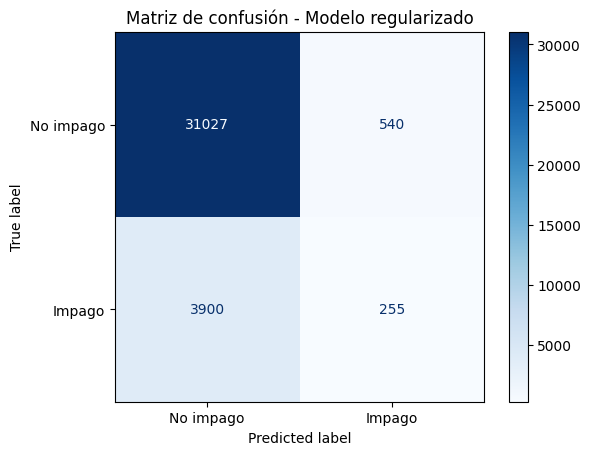

In [116]:
matriz = confusion_matrix(
    y_test,
    clasificacion_regularizada_nuevas,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["No impago", "Impago"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Modelo regularizado")
plt.show()

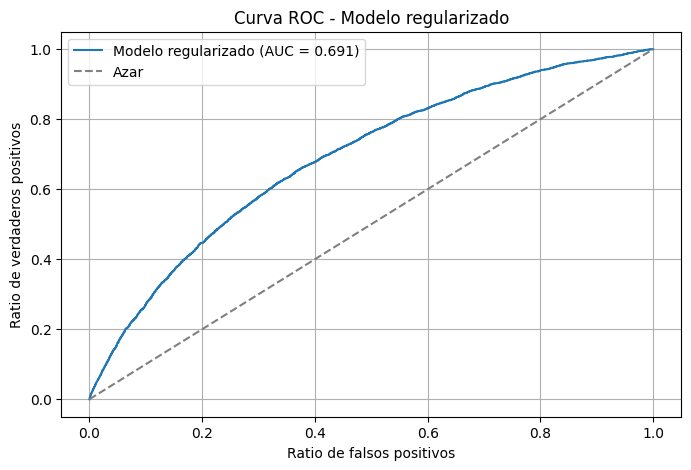

ROC-AUC: 0.6905


In [110]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, umbrales_roc = roc_curve(
    y_test,
    probabilidades_impago
)

auc = roc_auc_score(y_test, probabilidades_impago)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"Modelo regularizado (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Azar")

plt.xlabel("Ratio de falsos positivos")
plt.ylabel("Ratio de verdaderos positivos")
plt.title("Curva ROC - Modelo regularizado")
plt.legend()
plt.grid(True)
plt.show()

print("ROC-AUC:", round(auc, 4))

In [ ]:
coeficientes = pd.DataFrame({
    "Variable": X_train_reg.columns,
    "Coeficiente": modelo_regularizado.coef_[0]
})

coeficientes["Valor_absoluto"] = coeficientes["Coeficiente"].abs()

coeficientes = coeficientes.sort_values(
    "Valor_absoluto",
    ascending=False
)

coeficientes.round(4)

In [119]:
# Exportar las probabilidades del modelo de impago para entrenamiento
pd.DataFrame({
    "Impago_real": y_train,
    "Prob_Impago": probabilidades_cv
}).to_csv("prob_impago_train.csv", index=False)

# Exportar las probabilidades del modelo de impago para test
pd.DataFrame({
    "Impago_real": y_test,
    "Prob_Impago": probabilidades_impago
}).to_csv("prob_impago_test.csv", index=False)